<div style="font-family:Times New Roman;font-size:14pt;color:black"><b>Лабораторна робота 10</b><br>Згорткові нейронні мережі та перенесення навчання<br>Виконав Шиндир Олексій<br>4 курс, 10 група</div>

<a href="https://colab.research.google.com/github/raysewww-lang/mashynne-navchannia/blob/main/%D0%A8%D0%B8%D0%BD%D0%B4%D0%B8%D1%80_%D0%BF%D1%80_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Відкрити в Colab"/></a>

In [1]:
# Підготовка бібліотек і даних. Дані автоматично завантажуються з GitHub; резервний спосіб — data.zip.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
np.random.seed(25)
plt.rcParams.update({'font.family':'serif','font.serif':['Times New Roman','DejaVu Serif'],'font.size':14,'figure.figsize':(9,5)})
pd.set_option('display.max_columns',40)

def data_path(name):
    for folder in [Path('data'),Path('.'),Path('/content/data'),Path('/content')]:
        p=folder/name
        if p.exists():
            return p
    import zipfile, io
    from urllib.request import urlopen
    try:
        url='https://raw.githubusercontent.com/raysewww-lang/mashynne-navchannia/main/data.zip'
        with urlopen(url, timeout=60) as response:
            content=response.read()
        Path('data').mkdir(exist_ok=True)
        with zipfile.ZipFile(io.BytesIO(content)) as z:
            for member in z.namelist():
                if not member.endswith('/'):
                    (Path('data')/Path(member).name).write_bytes(z.read(member))
        if (Path('data')/name).exists():
            return Path('data')/name
    except Exception as error:
        print('Автоматичне завантаження недоступне:',error)
    from google.colab import files
    import zipfile, io
    print('Завантажте data.zip або файл',name)
    uploaded=files.upload()
    Path('data').mkdir(exist_ok=True)
    for fname,content in uploaded.items():
        if fname.endswith('.zip'):
            with zipfile.ZipFile(io.BytesIO(content)) as z:
                for member in z.namelist():
                    if not member.endswith('/'):
                        (Path('data')/Path(member).name).write_bytes(z.read(member))
        else:
            (Path('data')/Path(fname).name).write_bytes(content)
    p=Path('data')/name
    if not p.exists():
        raise FileNotFoundError(name)
    return p

In [2]:
# Підготовка TensorFlow і функцій оцінки.
import os
os.environ['TF_CPP_MIN_LOG_LEVEL']='2'
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.keras.utils.set_random_seed(25)
try:
    tf.config.threading.set_inter_op_parallelism_threads(2)
    tf.config.threading.set_intra_op_parallelism_threads(2)
except RuntimeError:
    pass
def callbacks():
    return [keras.callbacks.EarlyStopping(monitor='val_loss',patience=3,restore_best_weights=True),keras.callbacks.ReduceLROnPlateau(monitor='val_loss',factor=0.5,patience=2,min_lr=1e-6)]
def curves(history,title):
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for ax,metric in zip(axes,['loss','accuracy']):
        ax.plot(history.history[metric],label='Train')
        ax.plot(history.history['val_'+metric],label='Validation')
        ax.set(xlabel='Епоха',ylabel=metric,title=title);ax.legend()
    plt.tight_layout();plt.show()
def recognition(model,x,y,names):
    p=model.predict(x,verbose=0).argmax(axis=1)
    print(classification_report(y,p,target_names=names,zero_division=0))
    fig,axes=plt.subplots(2,5,figsize=(15,6))
    for i,ax in enumerate(axes.flat):
        ax.imshow(x[i].squeeze(),cmap='gray');ax.axis('off')
        ax.set_title('Іст.: '+names[int(y[i])]+'\nПр.: '+names[int(p[i])],fontsize=11)
    plt.tight_layout();plt.show()
    return p

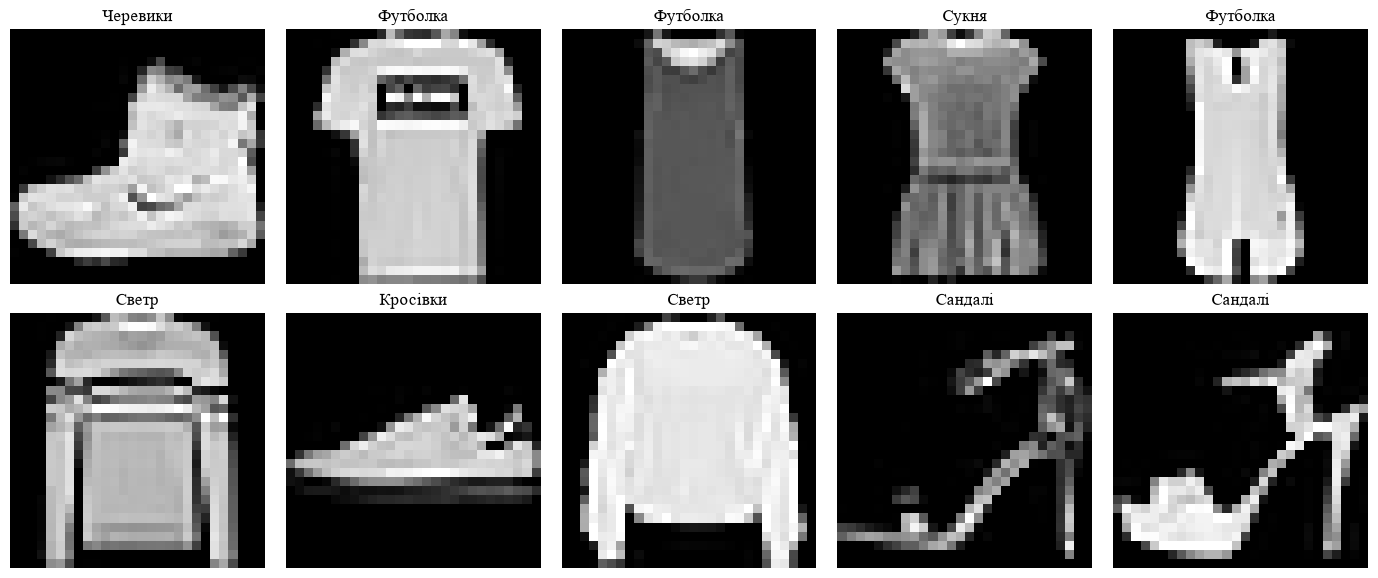

Для навчального експерименту стратифіковано обрано 12000 train, 3000 validation і 3000 незалежних test. Обидві моделі використовують однакові вибірки.


In [3]:
# Завдання 1. Пункти 1–2: завантажити fashion_mnist, показати 10 зображень, підготувати однакові вибірки для двох моделей.
(raw_x,raw_y),(raw_test,raw_test_y)=keras.datasets.fashion_mnist.load_data()
names=['Футболка','Штани','Светр','Сукня','Пальто','Сандалі','Сорочка','Кросівки','Сумка','Черевики']
fig,axes=plt.subplots(2,5,figsize=(14,6))
for i,ax in enumerate(axes.flat):
    ax.imshow(raw_x[i],cmap='gray');ax.set_title(names[raw_y[i]],fontsize=12);ax.axis('off')
plt.tight_layout();plt.show()
indices,_=train_test_split(np.arange(len(raw_y)),train_size=15000,stratify=raw_y,random_state=25)
test_indices,_=train_test_split(np.arange(len(raw_test_y)),train_size=3000,stratify=raw_test_y,random_state=25)
x=raw_x[indices].astype('float32')[...,None]/255;y=raw_y[indices]
x_test=raw_test[test_indices].astype('float32')[...,None]/255;y_test=raw_test_y[test_indices]
x_train,x_val,y_train,y_val=train_test_split(x,y,test_size=0.2,stratify=y,random_state=25)
print('Для навчального експерименту стратифіковано обрано 12000 train, 3000 validation і 3000 незалежних test. Обидві моделі використовують однакові вибірки.')

In [4]:
# Завдання 1. Пункти 3–5: архітектура CNN, оптимізатор Adam, batch 128, до 8 епох, callbacks і summary.
cnn=keras.Sequential([layers.Input((28,28,1)),layers.Conv2D(16,3,activation='relu'),layers.MaxPooling2D(),layers.Conv2D(32,3,activation='relu'),layers.MaxPooling2D(),layers.Flatten(),layers.Dense(64,activation='relu'),layers.Dropout(0.3),layers.Dense(10,activation='softmax')])
cnn.compile(optimizer=keras.optimizers.Adam(1e-3),loss='sparse_categorical_crossentropy',metrics=['accuracy'])
cnn.summary()
history=cnn.fit(x_train,y_train,validation_data=(x_val,y_val),epochs=8,batch_size=128,callbacks=callbacks(),verbose=2)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,714 (221.54 KB)

 Trainable params: 56,714 (221.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8


... (11 outputs left out)

Epoch 7/8


94/94 - 1s - 8ms/step - accuracy: 0.8375 - loss: 0.4415 - val_accuracy: 0.8553 - val_loss: 0.4088 - learning_rate: 0.0010


Epoch 8/8


94/94 - 1s - 8ms/step - accuracy: 0.8490 - loss: 0.4163 - val_accuracy: 0.8620 - val_loss: 0.3938 - learning_rate: 0.0010


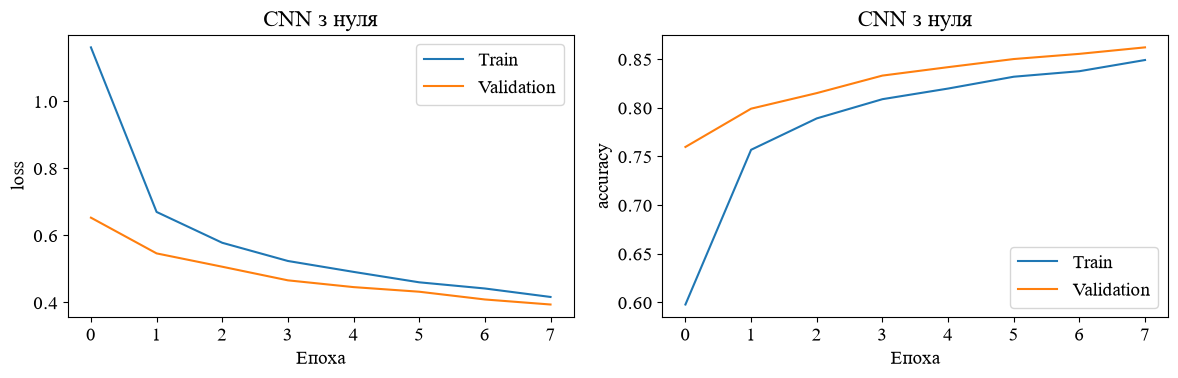

CNN test loss: 0.42480048537254333 accuracy: 0.8403333425521851


              precision    recall  f1-score   support

    Футболка       0.79      0.81      0.80       300
       Штани       0.98      0.96      0.97       300
       Светр       0.74      0.80      0.76       300
       Сукня       0.84      0.85      0.85       300
      Пальто       0.74      0.73      0.74       300
     Сандалі       0.92      0.97      0.94       300
     Сорочка       0.56      0.51      0.53       300
    Кросівки       0.93      0.90      0.92       300
       Сумка       0.94      0.95      0.95       300
    Черевики       0.94      0.92      0.93       300

    accuracy                           0.84      3000
   macro avg       0.84      0.84      0.84      3000
weighted avg       0.84      0.84      0.84      3000



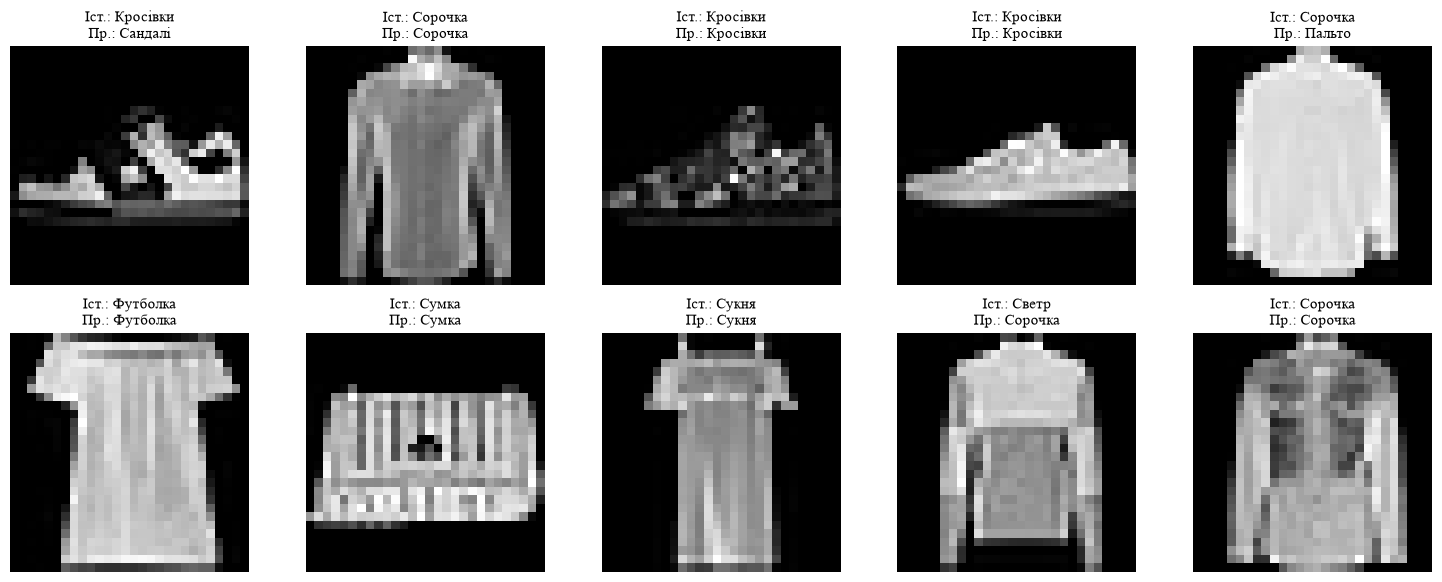

array([5, 6, 7, ..., 9, 3, 7], shape=(3000,))

In [5]:
# Завдання 1. Пункти 6–8: графіки loss/accuracy, classification report, візуалізація розпізнавання.
curves(history,'CNN з нуля')
cnn_loss,cnn_acc=cnn.evaluate(x_test,y_test,verbose=0)
print('CNN test loss:',cnn_loss,'accuracy:',cnn_acc)
recognition(cnn,x_test,y_test,names)

In [6]:
# Завдання 2. Попередньо навчена MobileNetV2 ImageNet. Заморозити базу, додати класифікатор і підготувати зображення.
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
base=MobileNetV2(weights='imagenet',include_top=False,input_shape=(96,96,3),alpha=0.35)
base.trainable=False
inputs=keras.Input((28,28,1))
z=layers.Resizing(96,96)(inputs)
z=layers.Concatenate()([z,z,z])
z=layers.Rescaling(2.0,offset=-1.0)(z)
z=base(z,training=False)
z=layers.GlobalAveragePooling2D()(z)
z=layers.Dropout(0.2)(z)
outputs=layers.Dense(10,activation='softmax')(z)
transfer=keras.Model(inputs,outputs)
transfer.compile(optimizer=keras.optimizers.Adam(1e-3),loss='sparse_categorical_crossentropy',metrics=['accuracy'])
transfer.summary()
warmup=transfer.fit(x_train,y_train,validation_data=(x_val,y_val),epochs=3,batch_size=64,callbacks=callbacks(),verbose=2)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resizing (Resizing) │ (None, 96, 96, 1) │          0 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 96, 96, 3) │          0 │ resizing[0][0],   │
│ (Concatenate)       │                   │            │ resizing[0][0],   │
│                     │                   │            │ resizing[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 96, 96, 3) │          0 │ concatenate[0][0] │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_0.35_96 │ (None, 3, 3,      │    410,208 │ rescaling[0][0]   │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ mobilenetv2_0.35… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 1280)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 10)        │     12,810 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 423,018 (1.61 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 410,208 (1.56 MB)

Epoch 1/3


188/188 - 17s - 88ms/step - accuracy: 0.7519 - loss: 0.6992 - val_accuracy: 0.8410 - val_loss: 0.4280 - learning_rate: 0.0010


Epoch 2/3


188/188 - 14s - 74ms/step - accuracy: 0.8478 - loss: 0.4274 - val_accuracy: 0.8590 - val_loss: 0.3807 - learning_rate: 0.0010


Epoch 3/3


188/188 - 11s - 58ms/step - accuracy: 0.8670 - loss: 0.3716 - val_accuracy: 0.8673 - val_loss: 0.3599 - learning_rate: 0.0010


In [7]:
# Завдання 2. Тонке налаштування: розморозити останні 15 шарів, зберегти BatchNormalization замороженими, малий learning rate і callbacks.
base.trainable=True
for layer in base.layers[:-15]:layer.trainable=False
for layer in base.layers:
    if isinstance(layer,layers.BatchNormalization):layer.trainable=False
transfer.compile(optimizer=keras.optimizers.Adam(1e-5),loss='sparse_categorical_crossentropy',metrics=['accuracy'])
print('Шарів, які донавчаються:',sum(layer.trainable for layer in base.layers))
fine=transfer.fit(x_train,y_train,validation_data=(x_val,y_val),epochs=3,batch_size=64,callbacks=callbacks(),verbose=2)
transfer.summary()

Шарів, які донавчаються: 10
Epoch 1/3


188/188 - 15s - 80ms/step - accuracy: 0.8773 - loss: 0.3392 - val_accuracy: 0.8703 - val_loss: 0.3493 - learning_rate: 1.0000e-05


Epoch 2/3


188/188 - 12s - 61ms/step - accuracy: 0.8804 - loss: 0.3234 - val_accuracy: 0.8697 - val_loss: 0.3455 - learning_rate: 1.0000e-05


Epoch 3/3


188/188 - 13s - 71ms/step - accuracy: 0.8859 - loss: 0.3155 - val_accuracy: 0.8703 - val_loss: 0.3420 - learning_rate: 1.0000e-05


... (2 outputs left out)

 Total params: 891,936 (3.40 MB)

 Trainable params: 234,458 (915.85 KB)

 Non-trainable params: 188,560 (736.56 KB)

 Optimizer params: 468,918 (1.79 MB)

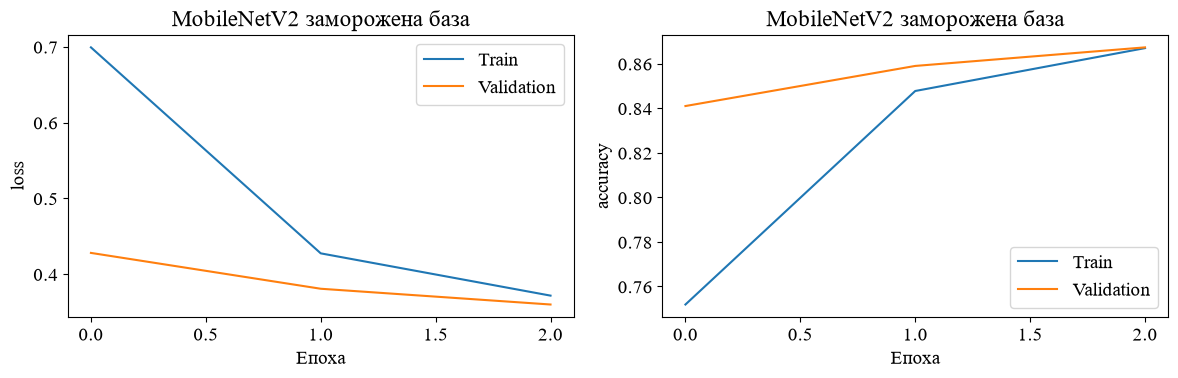

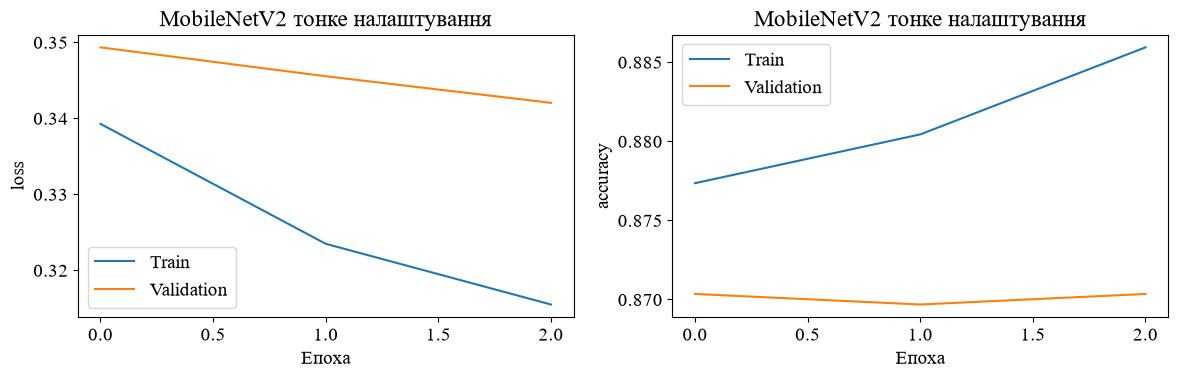

              precision    recall  f1-score   support

    Футболка       0.82      0.81      0.81       300
       Штани       0.99      0.97      0.98       300
       Светр       0.81      0.80      0.81       300
       Сукня       0.85      0.87      0.86       300
      Пальто       0.73      0.84      0.78       300
     Сандалі       0.97      0.98      0.97       300
     Сорочка       0.66      0.57      0.61       300
    Кросівки       0.92      0.97      0.95       300
       Сумка       0.96      0.97      0.97       300
    Черевики       0.98      0.93      0.96       300

    accuracy                           0.87      3000
   macro avg       0.87      0.87      0.87      3000
weighted avg       0.87      0.87      0.87      3000



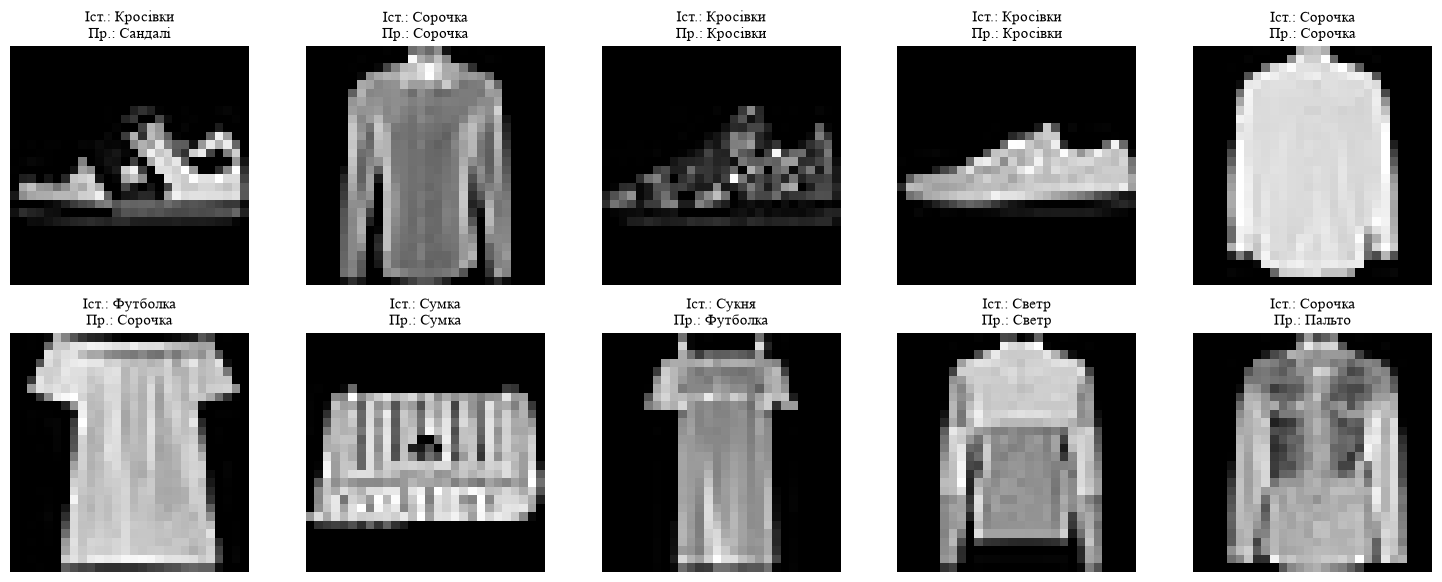

,Модель,Test accuracy,Test loss
0,CNN з нуля,0.840333,0.424800
1,MobileNetV2 fine-tuning,0.870667,0.349421


Різниця accuracy MobileNet - CNN: 0.030333340167999268


In [8]:
# Завдання 2. Повторити оцінку: криві навчання, loss, accuracy, classification report, візуалізація та порівняння.
curves(warmup,'MobileNetV2 заморожена база')
curves(fine,'MobileNetV2 тонке налаштування')
transfer_loss,transfer_acc=transfer.evaluate(x_test,y_test,batch_size=64,verbose=0)
recognition(transfer,x_test,y_test,names)
display(pd.DataFrame({'Модель':['CNN з нуля','MobileNetV2 fine-tuning'],'Test accuracy':[cnn_acc,transfer_acc],'Test loss':[cnn_loss,transfer_loss]}))
print('Різниця accuracy MobileNet - CNN:',transfer_acc-cnn_acc)
Path('models').mkdir(exist_ok=True)
cnn.save('models/Шиндир_пр_10_cnn.keras')
transfer.save('models/Шиндир_пр_10_transfer.keras')

In [9]:
# Висновок. Побудовано CNN з нуля та модель перенесення навчання MobileNetV2 з вагами ImageNet. Додано власний класифікатор, після початкового навчання розморожено частину бази. Обидві моделі оцінено на однаковому незалежному тесті. Таблиця показує, чи допомогло перенесення; воно не гарантує переваги на малих сірих зображеннях. Використано стратифіковану підвибірку, вказану на початку.